In [1]:
# %%
# ============= CELLULE 1: CONFIGURATION ET IMPORTS =============
import os
import sys
import cv2
import json
import torch
import numpy as np
import onnxruntime as ort
import time
import onnx
from tqdm import tqdm
import matplotlib.pyplot as plt
from collections import Counter

# Configuration matplotlib
%matplotlib inline

# Ajout du path pour les fonctions YOLOP
sys.path.append(os.getcwd())
from lib.core.general import non_max_suppression, box_iou, ap_per_class
from lib.core.evaluate import SegmentationMetric


In [2]:

# ============= CONSTANTES DE CONFIGURATION =============
CONF_THRES = 0.001
IOU_THRES = 0.6
IMG_SIZE = 640
BATCH_SIZE = 1  # Taille du batch pour l'inference
MAX_IMAGES = None  # None pour tout le dataset
TARGET_IMG = "b1c66a42-6f7d68ca.jpg"  # Image pour visualisation

# Chemins
BASE_DIR = os.getcwd()
VAL_DIR = os.path.join(BASE_DIR, "dataset/images/val")
ONNX_PATH = os.path.join(BASE_DIR, "weights/yolop-640-640-quantized-int8-INC.onnx")


In [3]:

# %%
# ============= CELLULE 2: FONCTION D'AUDIT DU MODELE =============
def audit_model_robust(model_path):
    """Audit detaille de la quantisation du modele ONNX"""
    print(f"\nAUDIT DU MODELE : {os.path.basename(model_path)}")
    print("-" * 70)
    
    if not os.path.exists(model_path):
        print("ERREUR : Fichier introuvable.")
        return
    
    # Chargement du modele
    model = onnx.load(model_path)
    graph = model.graph
    
    # Mapping des noeuds
    node_map = {}
    for node in graph.node:
        for output in node.output:
            node_map[output] = node
    
    # Stats de quantisation
    stats = {
        "Total": 0,
        "INT8 QLinear": 0, 
        "INT8 QDQ": 0,     
        "FP32": 0,
        "Autres": 0
    }
    
    fp32_layers = []
    int8_qlinear_layers = []
    int8_qdq_layers = []
    
    # Operations de calcul intensif a surveiller
    compute_ops = [
        'Conv', 'Gemm', 'MatMul', 'ConvTranspose',
        'QLinearConv', 'QLinearMatMul', 'QLinearGemm',
        'ConvInteger', 'MatMulInteger'
    ]
    
    # Analyse de chaque noeud
    for node in graph.node:
        if node.op_type in compute_ops:
            stats["Total"] += 1
            layer_name = node.name if node.name else f"{node.op_type}_{stats['Total']}"
            
            # Detection INT8 natif (QLinear ou Integer)
            if 'QLinear' in node.op_type or 'Integer' in node.op_type:
                stats["INT8 QLinear"] += 1
                int8_qlinear_layers.append((layer_name, node.op_type))
                continue
            
            # Detection INT8 via QDQ (QuantizeLinear/DequantizeLinear)
            is_quantized_input = False
            for inp_name in node.input[:2]:
                if inp_name in node_map:
                    parent = node_map[inp_name]
                    if parent.op_type == "DequantizeLinear":
                        is_quantized_input = True
                        break
            
            if is_quantized_input:
                stats["INT8 QDQ"] += 1
                int8_qdq_layers.append((layer_name, node.op_type))
            else:
                stats["FP32"] += 1
                fp32_layers.append((layer_name, node.op_type))
    
    # Calcul du taux de quantisation
    total_int8 = stats["INT8 QLinear"] + stats["INT8 QDQ"]
    quant_ratio = (total_int8 / stats["Total"] * 100) if stats["Total"] > 0 else 0
    
    # Affichage des resultats
    print(f"REPARTITION DES COUCHES DE CALCUL :")
    print(f"  Total Layers           : {stats['Total']}")
    print(f"  INT8 QLinear (Natif)   : {stats['INT8 QLinear']} (Optimisation CPU maximale)")
    print(f"  INT8 QDQ (Pattern)     : {stats['INT8 QDQ']} (Compatible NPU/GPU)")
    print(f"  FP32 (Non quantifie)   : {stats['FP32']}")
    print(f"  {'=' * 70}")
    print(f"  Taux de Quantisation   : {quant_ratio:.2f}%")
    print("-" * 70)
    
    # Details des couches FP32 (potentiellement problematiques)
    if stats["FP32"] > 0:
        print(f"\nCOUCHES RESTEES EN FP32 ({stats['FP32']}) :")
        for i, (name, op_type) in enumerate(fp32_layers[:15]):
            print(f"  {i+1:2d}. {name[:50]:50s} ({op_type})")
        if len(fp32_layers) > 15:
            print(f"  ... et {len(fp32_layers) - 15} autres couches")
    else:
        print("\nATTENTION : Aucune couche FP32 detectee.")
        print("Verifiez que les sorties du modele ne sont pas quantifiees (perte de precision).")
    
    # Distribution des types d'operations
    op_types = [op for _, op in int8_qlinear_layers + int8_qdq_layers + fp32_layers]
    op_counts = Counter(op_types)
    
    print(f"\nDISTRIBUTION DES TYPES D'OPERATIONS :")
    for op_type, count in op_counts.most_common():
        print(f"  {op_type:20s} : {count:3d}")
    
    print("-" * 70 + "\n")
    
    return {
        "total": stats["Total"],
        "int8_qlinear": stats["INT8 QLinear"],
        "int8_qdq": stats["INT8 QDQ"],
        "fp32": stats["FP32"],
        "quantization_ratio": quant_ratio
    }


In [4]:

# %%
# ============= CELLULE 3: DatasetImage (Visualisation) =============
class DatasetImage:
    """Classe pour traiter une seule image avec letterbox"""
    
    def __init__(self, img_path, model_path=None, session=None):
        self.session = session
        self.img_path = img_path
        self.model_path = model_path
        
        if not os.path.exists(self.img_path):
            raise FileNotFoundError(f"Image introuvable : {self.img_path}")
            
        self.img_bgr = cv2.imread(self.img_path)
        self.img_rgb = cv2.cvtColor(self.img_bgr, cv2.COLOR_BGR2RGB)
        self.h_orig, self.w_orig = self.img_rgb.shape[:2]
        
        # Chemins Ground Truth
        self.da_path, self.ll_path, self.det_path = self._get_gt_paths()
        
        # Resultats
        self.pred_da = None
        self.pred_ll = None
        self.pred_boxes = None
        self.gt_da = None
        self.gt_ll = None
        self.gt_boxes = None
        
        # Infos letterbox
        self.r = None
        self.dw = None
        self.dh = None
        self.new_w = None
        self.new_h = None
        
        self.inference_time = 0
    
    def _get_gt_paths(self):
        da_path = self.img_path.replace("images", "da_seg_annotations").replace(".jpg", ".png")
        ll_path = self.img_path.replace("images", "ll_seg_annotations").replace(".jpg", ".png")
        det_path = self.img_path.replace("images", "det_annotations").replace(".jpg", ".json")
        return da_path, ll_path, det_path
    
    def _letterbox(self, img, new_shape=640):
        """Letterbox resize avec padding"""
        shape = img.shape[:2]
        if isinstance(new_shape, int):
            new_shape = (new_shape, new_shape)
        
        # Ratio et nouvelles dimensions
        r = min(new_shape[0] / shape[0], new_shape[1] / shape[1])
        new_unpad = (int(round(shape[1] * r)), int(round(shape[0] * r)))
        
        # Padding
        dw = (new_shape[1] - new_unpad[0]) // 2
        dh = (new_shape[0] - new_unpad[1]) // 2
        
        # Resize
        if shape[::-1] != new_unpad:
            img = cv2.resize(img, new_unpad, interpolation=cv2.INTER_LINEAR)
        
        # Padding avec valeur 114
        top, bottom = dh, new_shape[0] - new_unpad[1] - dh
        left, right = dw, new_shape[1] - new_unpad[0] - dw
        img = cv2.copyMakeBorder(img, top, bottom, left, right, cv2.BORDER_CONSTANT, value=(114, 114, 114))
        
        return img, r, dw, dh, new_unpad[0], new_unpad[1]
    
    def load_ground_truth(self):
        """Charge les GT avec binarisation"""
        # 1. Masques de segmentation
        if os.path.exists(self.da_path):
            self.gt_da = cv2.imread(self.da_path, cv2.IMREAD_GRAYSCALE)
            if self.gt_da is not None:
                self.gt_da = (self.gt_da > 0).astype(np.uint8)
                if self.gt_da.shape != (self.h_orig, self.w_orig):
                    self.gt_da = cv2.resize(self.gt_da, (self.w_orig, self.h_orig), 
                                           interpolation=cv2.INTER_NEAREST)
        
        if os.path.exists(self.ll_path):
            self.gt_ll = cv2.imread(self.ll_path, cv2.IMREAD_GRAYSCALE)
            if self.gt_ll is not None:
                self.gt_ll = (self.gt_ll > 0).astype(np.uint8)
                if self.gt_ll.shape != (self.h_orig, self.w_orig):
                    self.gt_ll = cv2.resize(self.gt_ll, (self.w_orig, self.h_orig), 
                                           interpolation=cv2.INTER_NEAREST)
        
        # 2. Boites de detection
        self.gt_boxes = []
        if os.path.exists(self.det_path):
            try:
                with open(self.det_path, 'r') as f:
                    data = json.load(f)
                frames = data.get('frames', [])
                if frames:
                    objects = frames[0].get('objects', [])
                    for obj in objects:
                        if obj.get('category') == 'car':
                            box2d = obj.get('box2d', {})
                            if box2d:
                                self.gt_boxes.append([
                                    0,
                                    float(box2d['x1']), float(box2d['y1']),
                                    float(box2d['x2']), float(box2d['y2'])
                                ])
            except Exception:
                pass
        
        self.gt_boxes = np.array(self.gt_boxes) if len(self.gt_boxes) > 0 else np.zeros((0, 5))
    
    def run_inference(self):
        if self.session is None:
            sess_options = ort.SessionOptions()
            sess_options.log_severity_level = 3
            providers = ['CUDAExecutionProvider', 'CPUExecutionProvider']
            self.session = ort.InferenceSession(self.model_path, sess_options=sess_options, providers=providers)
        
        # Letterbox preprocessing
        img_letterbox, self.r, self.dw, self.dh, self.new_w, self.new_h = self._letterbox(
            self.img_rgb, IMG_SIZE
        )
        
        # Normalisation
        img_input = img_letterbox.astype(np.float32) / 255.0
        img_input = (img_input - [0.485, 0.456, 0.406]) / [0.229, 0.224, 0.225]
        img_input = img_input.transpose(2, 0, 1)[None].astype(np.float32)
        
        # Inference
        start_time = time.time()
        outputs = self.session.run(
            ['det_out', 'drive_area_seg', 'lane_line_seg'], 
            {self.session.get_inputs()[0].name: img_input}
        )
        self.inference_time = (time.time() - start_time) * 1000
        
        det_out, da_seg_out, ll_seg_out = outputs
        
        # Segmentation (avec crop du padding)
        da_pred = np.argmax(da_seg_out, axis=1)[0]
        ll_pred = np.argmax(ll_seg_out, axis=1)[0]
        
        # Retirer le padding
        da_pred = da_pred[self.dh : self.dh + self.new_h, self.dw : self.dw + self.new_w]
        ll_pred = ll_pred[self.dh : self.dh + self.new_h, self.dw : self.dw + self.new_w]
        
        # Resize vers taille originale
        self.pred_da = cv2.resize(da_pred.astype(np.uint8), (self.w_orig, self.h_orig), 
                                  interpolation=cv2.INTER_NEAREST)
        self.pred_ll = cv2.resize(ll_pred.astype(np.uint8), (self.w_orig, self.h_orig), 
                                  interpolation=cv2.INTER_NEAREST)
        
        # Detection (avec correction letterbox)
        det_tensor = torch.from_numpy(det_out).float()
        nms_out = non_max_suppression(det_tensor, conf_thres=CONF_THRES, iou_thres=IOU_THRES)
        
        if nms_out[0] is not None and len(nms_out[0]) > 0:
            pred_boxes = nms_out[0].cpu().numpy()
            
            # Correction letterbox
            pred_boxes[:, [0, 2]] -= self.dw
            pred_boxes[:, [1, 3]] -= self.dh
            pred_boxes[:, :4] /= self.r
            
            # Clamp aux dimensions originales
            pred_boxes[:, 0] = np.clip(pred_boxes[:, 0], 0, self.w_orig)
            pred_boxes[:, 2] = np.clip(pred_boxes[:, 2], 0, self.w_orig)
            pred_boxes[:, 1] = np.clip(pred_boxes[:, 1], 0, self.h_orig)
            pred_boxes[:, 3] = np.clip(pred_boxes[:, 3], 0, self.h_orig)
            
            self.pred_boxes = pred_boxes
        else:
            self.pred_boxes = np.zeros((0, 6))
    
    def visualize(self):
        """Genere la visualisation : Originale | GT | Prediction"""
        def draw_overlay(img, da, ll, boxes, box_type='pred', color=(0, 255, 0)):
            res = img.copy()
            # Segmentation (Transparence)
            color_mask = np.zeros_like(res)
            if da is not None: 
                color_mask[da == 1] = [0, 255, 0]
            if ll is not None: 
                color_mask[ll == 1] = [255, 0, 0]
            
            mask_indices = np.any(color_mask != 0, axis=-1)
            res[mask_indices] = res[mask_indices] * 0.6 + color_mask[mask_indices] * 0.4
            
            # Detection (Boites)
            if boxes is not None and len(boxes) > 0:
                for box in boxes:
                    if box_type == 'gt': 
                        x1, y1, x2, y2 = map(int, box[1:5])
                    else: 
                        x1, y1, x2, y2 = map(int, box[:4])
                    cv2.rectangle(res, (x1, y1), (x2, y2), color, 2)
            return res
        
        # Creation des images
        viz_gt = draw_overlay(self.img_rgb, self.gt_da, self.gt_ll, self.gt_boxes, 'gt', (255, 255, 0))
        viz_pred = draw_overlay(self.img_rgb, self.pred_da, self.pred_ll, self.pred_boxes, 'pred', (0, 140, 255))
        
        # Affichage Matplotlib
        plt.figure(figsize=(24, 8))
        
        plt.subplot(1, 3, 1)
        plt.imshow(self.img_rgb)
        plt.title("Image Originale")
        plt.axis('off')
        
        plt.subplot(1, 3, 2)
        plt.imshow(viz_gt)
        plt.title("Realite Terrain (GT)\n(Jaune=Autos, Vert=Route, Rouge=Lignes)")
        plt.axis('off')
        
        plt.subplot(1, 3, 3)
        plt.imshow(viz_pred)
        plt.title("Prediction Modele\n(Orange=Autos, Vert=Route, Rouge=Lignes)")
        plt.axis('off')
        
        plt.tight_layout()
        plt.show()


In [5]:

# %%
# ============= CELLULE 4: DatasetBatch (Inference par batch) =============
class DatasetBatch:
    """Classe pour traiter des images par batch (optimisation vitesse)"""
    
    def __init__(self, img_paths, session, batch_size=8):
        self.img_paths = img_paths
        self.session = session
        self.batch_size = batch_size
        
        # Stockage des resultats
        self.results = []
    
    @staticmethod
    def letterbox(img, new_shape=640):
        """Letterbox resize statique pour batch processing"""
        shape = img.shape[:2]
        if isinstance(new_shape, int):
            new_shape = (new_shape, new_shape)
        
        r = min(new_shape[0] / shape[0], new_shape[1] / shape[1])
        new_unpad = (int(round(shape[1] * r)), int(round(shape[0] * r)))
        
        dw = (new_shape[1] - new_unpad[0]) // 2
        dh = (new_shape[0] - new_unpad[1]) // 2
        
        if shape[::-1] != new_unpad:
            img = cv2.resize(img, new_unpad, interpolation=cv2.INTER_LINEAR)
        
        top, bottom = dh, new_shape[0] - new_unpad[1] - dh
        left, right = dw, new_shape[1] - new_unpad[0] - dw
        img = cv2.copyMakeBorder(img, top, bottom, left, right, cv2.BORDER_CONSTANT, value=(114, 114, 114))
        
        return img, r, dw, dh, new_unpad[0], new_unpad[1]
    
    def load_ground_truth(self, img_path):
        """Charge les GT pour une image"""
        da_path = img_path.replace("images", "da_seg_annotations").replace(".jpg", ".png")
        ll_path = img_path.replace("images", "ll_seg_annotations").replace(".jpg", ".png")
        det_path = img_path.replace("images", "det_annotations").replace(".jpg", ".json")
        
        # Lire l'image pour obtenir dimensions originales
        img = cv2.imread(img_path)
        h_orig, w_orig = img.shape[:2]
        
        # Ground truth segmentation
        gt_da = None
        if os.path.exists(da_path):
            gt_da = cv2.imread(da_path, cv2.IMREAD_GRAYSCALE)
            if gt_da is not None:
                gt_da = (gt_da > 0).astype(np.uint8)
                if gt_da.shape != (h_orig, w_orig):
                    gt_da = cv2.resize(gt_da, (w_orig, h_orig), interpolation=cv2.INTER_NEAREST)
        
        gt_ll = None
        if os.path.exists(ll_path):
            gt_ll = cv2.imread(ll_path, cv2.IMREAD_GRAYSCALE)
            if gt_ll is not None:
                gt_ll = (gt_ll > 0).astype(np.uint8)
                if gt_ll.shape != (h_orig, w_orig):
                    gt_ll = cv2.resize(gt_ll, (w_orig, h_orig), interpolation=cv2.INTER_NEAREST)
        
        # Ground truth detection
        gt_boxes = []
        if os.path.exists(det_path):
            try:
                with open(det_path, 'r') as f:
                    data = json.load(f)
                frames = data.get('frames', [])
                if frames:
                    objects = frames[0].get('objects', [])
                    for obj in objects:
                        if obj.get('category') == 'car':
                            box2d = obj.get('box2d', {})
                            if box2d:
                                gt_boxes.append([
                                    0,
                                    float(box2d['x1']), float(box2d['y1']),
                                    float(box2d['x2']), float(box2d['y2'])
                                ])
            except Exception:
                pass
        
        gt_boxes = np.array(gt_boxes) if len(gt_boxes) > 0 else np.zeros((0, 5))
        
        return gt_da, gt_ll, gt_boxes, h_orig, w_orig
    
    def process_batch(self, batch_paths):
        """Traite un batch d'images"""
        batch_images = []
        batch_metadata = []
        
        # Preparation du batch
        for img_path in batch_paths:
            img_bgr = cv2.imread(img_path)
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            h_orig, w_orig = img_rgb.shape[:2]
            
            # Letterbox
            img_letterbox, r, dw, dh, new_w, new_h = self.letterbox(img_rgb, IMG_SIZE)
            
            # Normalisation
            img_input = img_letterbox.astype(np.float32) / 255.0
            img_input = (img_input - [0.485, 0.456, 0.406]) / [0.229, 0.224, 0.225]
            img_input = img_input.transpose(2, 0, 1)
            
            batch_images.append(img_input)
            batch_metadata.append({
                'path': img_path,
                'h_orig': h_orig,
                'w_orig': w_orig,
                'r': r,
                'dw': dw,
                'dh': dh,
                'new_w': new_w,
                'new_h': new_h
            })
        
        # Inference batch
        batch_input = np.array(batch_images, dtype=np.float32)
        
        start_time = time.time()
        outputs = self.session.run(
            ['det_out', 'drive_area_seg', 'lane_line_seg'],
            {self.session.get_inputs()[0].name: batch_input}
        )
        batch_time = (time.time() - start_time) * 1000
        
        det_out, da_seg_out, ll_seg_out = outputs
        
        # Post-traitement pour chaque image du batch
        for i, metadata in enumerate(batch_metadata):
            # Segmentation
            da_pred = np.argmax(da_seg_out[i], axis=0)
            ll_pred = np.argmax(ll_seg_out[i], axis=0)
            
            # Retirer padding
            dh, dw = metadata['dh'], metadata['dw']
            new_h, new_w = metadata['new_h'], metadata['new_w']
            
            da_pred = da_pred[dh:dh+new_h, dw:dw+new_w]
            ll_pred = ll_pred[dh:dh+new_h, dw:dw+new_w]
            
            # Resize vers taille originale
            h_orig, w_orig = metadata['h_orig'], metadata['w_orig']
            pred_da = cv2.resize(da_pred.astype(np.uint8), (w_orig, h_orig), 
                                interpolation=cv2.INTER_NEAREST)
            pred_ll = cv2.resize(ll_pred.astype(np.uint8), (w_orig, h_orig), 
                                interpolation=cv2.INTER_NEAREST)
            
            # Detection
            det_tensor = torch.from_numpy(det_out[i:i+1]).float()
            nms_out = non_max_suppression(det_tensor, conf_thres=CONF_THRES, iou_thres=IOU_THRES)
            
            if nms_out[0] is not None and len(nms_out[0]) > 0:
                pred_boxes = nms_out[0].cpu().numpy()
                
                # Correction letterbox
                r = metadata['r']
                pred_boxes[:, [0, 2]] -= dw
                pred_boxes[:, [1, 3]] -= dh
                pred_boxes[:, :4] /= r
                
                # Clamp
                pred_boxes[:, 0] = np.clip(pred_boxes[:, 0], 0, w_orig)
                pred_boxes[:, 2] = np.clip(pred_boxes[:, 2], 0, w_orig)
                pred_boxes[:, 1] = np.clip(pred_boxes[:, 1], 0, h_orig)
                pred_boxes[:, 3] = np.clip(pred_boxes[:, 3], 0, h_orig)
            else:
                pred_boxes = np.zeros((0, 6))
            
            # Charger GT
            gt_da, gt_ll, gt_boxes, _, _ = self.load_ground_truth(metadata['path'])
            
            self.results.append({
                'path': metadata['path'],
                'pred_da': pred_da,
                'pred_ll': pred_ll,
                'pred_boxes': pred_boxes,
                'gt_da': gt_da,
                'gt_ll': gt_ll,
                'gt_boxes': gt_boxes,
                'time': batch_time / len(batch_paths)
            })
    
    def process_all(self):
        """Traite toutes les images par batch"""
        num_batches = (len(self.img_paths) + self.batch_size - 1) // self.batch_size
        
        for i in tqdm(range(num_batches), desc="Processing batches"):
            start_idx = i * self.batch_size
            end_idx = min((i + 1) * self.batch_size, len(self.img_paths))
            batch_paths = self.img_paths[start_idx:end_idx]
            
            try:
                self.process_batch(batch_paths)
            except Exception as e:
                print(f"\nErreur batch {i}: {e}")
                # Traiter les images individuellement en cas d'erreur
                for path in batch_paths:
                    try:
                        self.process_batch([path])
                    except Exception as e2:
                        print(f"Erreur image {os.path.basename(path)}: {e2}")


In [6]:

# %%
# ============= CELLULE 5: DatasetFull (Evaluation complete) =============
class DatasetFull:
    """Evaluation complete du dataset avec inference par batch"""
    
    def __init__(self, img_dir, model_path, max_images=None, batch_size=8):
        self.img_dir = img_dir
        self.model_path = model_path
        self.batch_size = batch_size
        
        self.image_files = sorted([
            os.path.join(img_dir, f) 
            for f in os.listdir(img_dir) 
            if f.endswith('.jpg')
        ])
        
        if max_images:
            self.image_files = self.image_files[:max_images]
        
        print(f"Dataset: {len(self.image_files)} images (batch_size={batch_size})")
        
        # Session ONNX unique
        self.session = None
        if self.model_path and os.path.exists(self.model_path):
            sess_options = ort.SessionOptions()
            sess_options.log_severity_level = 3
            providers = ['CUDAExecutionProvider', 'CPUExecutionProvider']
            print("Chargement du modele ONNX...")
            self.session = ort.InferenceSession(
                self.model_path, 
                sess_options=sess_options, 
                providers=providers
            )
        
        # Metriques
        self.da_metric = SegmentationMetric(2)
        self.ll_metric = SegmentationMetric(2)
        
        # Detection stats
        self.det_stats = []
        
        # IoU thresholds
        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.iouv = torch.linspace(0.5, 0.95, 10).to(device)
        self.niou = self.iouv.numel()
        self.device = device
        
        self.times = []
    
    def process_all(self):
        """Traitement par batch de toutes les images"""
        print("Evaluation en cours...")
        
        # Utiliser DatasetBatch pour l'inference
        batch_processor = DatasetBatch(self.image_files, self.session, self.batch_size)
        batch_processor.process_all()
        
        # Collecter les resultats
        for result in batch_processor.results:
            # Speed
            self.times.append(result['time'])
            
            # Segmentation
            if result['pred_da'] is not None and result['gt_da'] is not None:
                self.da_metric.addBatch(result['pred_da'], result['gt_da'])
            
            if result['pred_ll'] is not None and result['gt_ll'] is not None:
                self.ll_metric.addBatch(result['pred_ll'], result['gt_ll'])
            
            # Detection
            self._process_detection_stats(
                result['pred_boxes'], 
                result['gt_boxes']
            )
    
    def _process_detection_stats(self, pred_boxes, gt_boxes):
        """Calcule les stats de detection"""
        pred = torch.from_numpy(pred_boxes).float().to(self.device)
        labels = torch.from_numpy(gt_boxes).float().to(self.device)
        
        nl = len(labels)
        tcls = labels[:, 0].tolist() if nl else []
        
        if len(pred) == 0:
            if nl:
                self.det_stats.append((
                    torch.zeros(0, self.niou, dtype=torch.bool),
                    torch.Tensor(),
                    torch.Tensor(),
                    tcls
                ))
            return
        
        # Calcul IoU et matching
        correct = torch.zeros(pred.shape[0], self.niou, dtype=torch.bool, device=self.device)
        
        if nl:
            detected = []
            tcls_tensor = labels[:, 0]
            tbox = labels[:, 1:5]
            
            for cls in torch.unique(tcls_tensor):
                ti = (tcls_tensor == cls).nonzero(as_tuple=False).view(-1)
                pi = (pred[:, 5] == cls).nonzero(as_tuple=False).view(-1)
                
                if pi.shape[0]:
                    ious, idx = box_iou(pred[pi, :4], tbox[ti]).max(1)
                    
                    for j in (ious > self.iouv[0]).nonzero(as_tuple=False):
                        d = ti[idx[j]]
                        if d.item() not in detected:
                            detected.append(d.item())
                            correct[pi[j]] = ious[j] > self.iouv
                            if len(detected) == nl:
                                break
        
        self.det_stats.append((
            correct.cpu(),
            pred[:, 4].cpu(),
            pred[:, 5].cpu(),
            tcls
        ))
    
    def compute_metrics(self):
        """Calcul des metriques finales"""
        print("\n" + "="*60)
        print("YOLOP EVALUATION RESULTS")
        print("="*60)
        
        # Speed
        avg_time = np.mean(self.times)
        fps = 1000 / avg_time if avg_time > 0 else 0
        
        # Detection
        recall_val = 0.0
        map50_val = 0.0
        
        if len(self.det_stats):
            stats = [np.concatenate(x, 0) for x in zip(*self.det_stats)]
            
            if stats[0].any():
                p, r, ap, f1, ap_class = ap_per_class(
                    *stats, plot=False, save_dir=None, names={0: 'car'}
                )
                ap50 = ap[:, 0]
                
                recall_val = r.mean()
                map50_val = ap50.mean()
        
        print("Traffic Object Detection Result")
        print(f"    Recall(%): {recall_val*100:.2f}")
        print(f"    Speed(fps): {fps:.2f}")
        print(f"    mAP50(%): {map50_val*100:.2f}")
        
        # Drivable Area Segmentation
        da_miou = self.da_metric.meanIntersectionOverUnion()
        
        print("Drivable Area Segmentation Result")
        print(f"    mIOU(%): {da_miou*100:.2f}")
        print(f"    Speed(fps): {fps:.2f}")
        
        # Lane Detection
        ll_miou = self.ll_metric.meanIntersectionOverUnion()
        ll_iou = self.ll_metric.IntersectionOverUnion()
        
        print("Lane Detection Result")
        print(f"    mIOU(%): {ll_miou*100:.2f}")
        print(f"    IOU(%): {ll_iou*100:.2f}")
        
        print("="*60)



DIAGNOSTIC MATERIEL
PyTorch : CUDA (GPU)
  Carte Graphique : NVIDIA GeForce RTX 5060 Ti
  Memoire VRAM    : 16.61 GB
----------------------------------------------------------------------
ONNX Runtime Providers : ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']
ONNX peut utiliser le GPU (CUDA detecte)


AUDIT DU MODELE : yolop-640-640-quantized-int8-INC.onnx
----------------------------------------------------------------------
REPARTITION DES COUCHES DE CALCUL :
  Total Layers           : 102
  INT8 QLinear (Natif)   : 102 (Optimisation CPU maximale)
  INT8 QDQ (Pattern)     : 0 (Compatible NPU/GPU)
  FP32 (Non quantifie)   : 0
  Taux de Quantisation   : 100.00%
----------------------------------------------------------------------

ATTENTION : Aucune couche FP32 detectee.
Verifiez que les sorties du modele ne sont pas quantifiees (perte de precision).

DISTRIBUTION DES TYPES D'OPERATIONS :
  QLinearConv          : 102
-----------------------------------

/usr/local/lib/python3.10/dist-packages/torch/cuda/__init__.py:234: UserWarning: 
NVIDIA GeForce RTX 5060 Ti with CUDA capability sm_120 is not compatible with the current PyTorch installation.
The current PyTorch install supports CUDA capabilities sm_52 sm_60 sm_61 sm_70 sm_72 sm_75 sm_80 sm_86 sm_87 sm_90 compute_90.
If you want to use the NVIDIA GeForce RTX 5060 Ti GPU with PyTorch, please check the instructions at https://pytorch.org/get-started/locally/

  warnings.warn(


Evaluation en cours...


Processing batches: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████| 10000/10000 [16:58<00:00,  9.81it/s]



YOLOP EVALUATION RESULTS
Traffic Object Detection Result
    Recall(%): 88.54
    Speed(fps): 19.34
    mAP50(%): 68.59
Drivable Area Segmentation Result
    mIOU(%): 91.10
    Speed(fps): 19.34
Lane Detection Result
    mIOU(%): 59.91
    IOU(%): 21.27

VISUALISATION D'UNE IMAGE


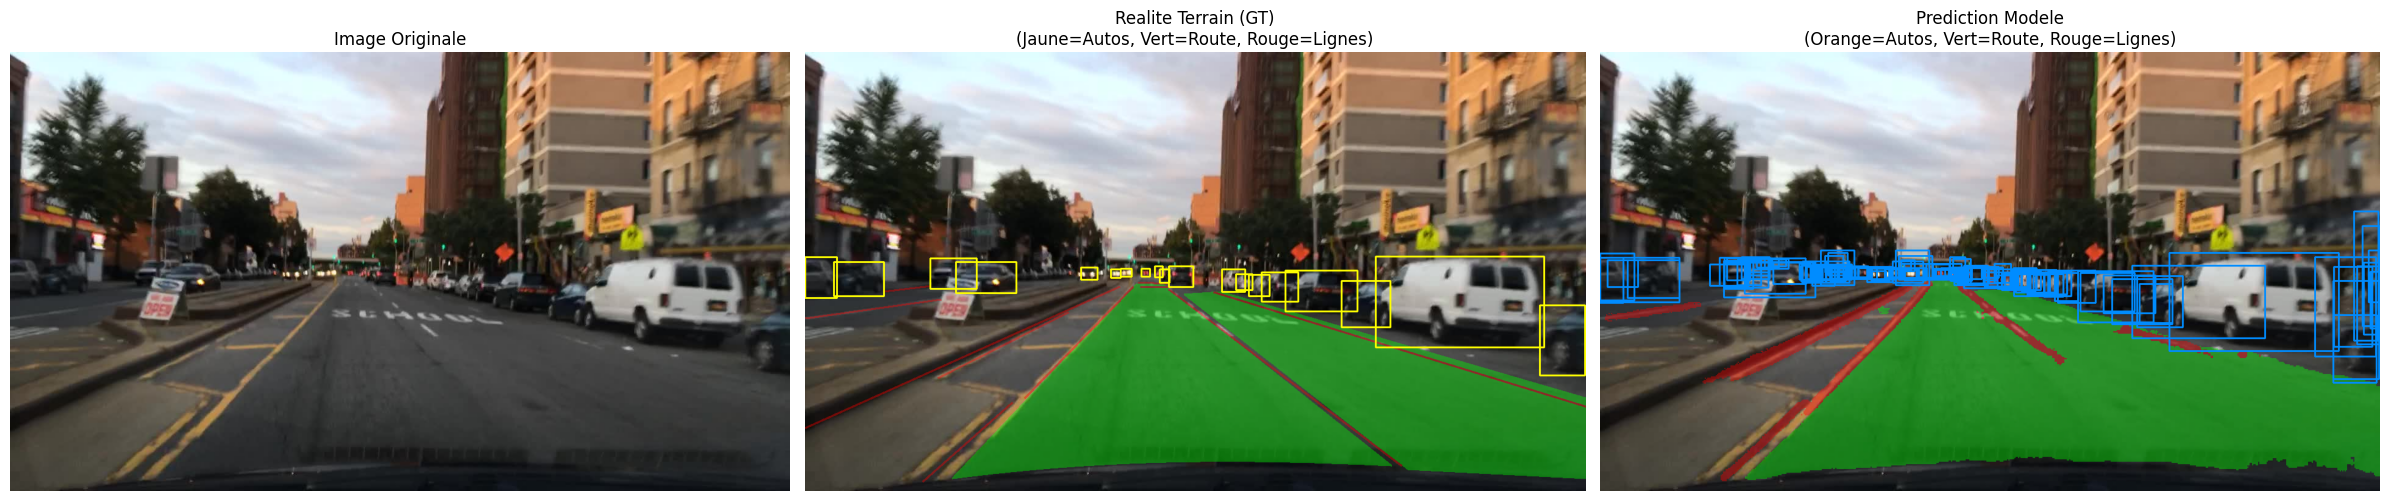

Visualisation generee pour : b1c66a42-6f7d68ca.jpg


In [7]:

# %%
# ============= CELLULE 6: MAIN =============
if __name__ == "__main__":
    # Diagnostic materiel
    print("\n" + "="*70)
    print("DIAGNOSTIC MATERIEL")
    print("="*70)
    
    # PyTorch
    if torch.cuda.is_available():
        print(f"PyTorch : CUDA (GPU)")
        print(f"  Carte Graphique : {torch.cuda.get_device_name(0)}")
        print(f"  Memoire VRAM    : {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
    else:
        print("PyTorch : CPU")
    
    # ONNX Runtime
    print("-" * 70)
    providers = ort.get_available_providers()
    print(f"ONNX Runtime Providers : {providers}")
    
    if 'CUDAExecutionProvider' in providers:
        print("ONNX peut utiliser le GPU (CUDA detecte)")
    else:
        print("ONNX utilisera le CPU")
    print("="*70 + "\n")
    
    # Audit du modele
    if os.path.exists(ONNX_PATH):
        audit_model_robust(ONNX_PATH)
    
    # Verification des chemins
    if not os.path.exists(VAL_DIR):
        print(f"ERREUR : Dossier introuvable : {VAL_DIR}")
    elif not os.path.exists(ONNX_PATH):
        print(f"ERREUR : Modele introuvable : {ONNX_PATH}")
    else:
        # Evaluation globale avec batch
        print("\n" + "="*70)
        print("EVALUATION GLOBALE DU DATASET")
        print("="*70)
        evaluator = DatasetFull(VAL_DIR, ONNX_PATH, max_images=MAX_IMAGES, batch_size=BATCH_SIZE)
        evaluator.process_all()
        evaluator.compute_metrics()
        
        # Visualisation d'une image specifique
        print("\n" + "="*70)
        print("VISUALISATION D'UNE IMAGE")
        print("="*70)
        target_path = os.path.join(VAL_DIR, TARGET_IMG)
        
        if os.path.exists(target_path):
            try:
                vis_obj = DatasetImage(target_path, ONNX_PATH)
                vis_obj.load_ground_truth()
                vis_obj.run_inference()
                vis_obj.visualize()
                print(f"Visualisation generee pour : {TARGET_IMG}")
            except Exception as e:
                print(f"Erreur visualisation : {e}")
        else:
            print(f"Image cible introuvable : {target_path}")

# %%